# Explore the PLAN pipeline

Same flow as `src/pipelines/digital_english.py`, exposed one step at a time so you can:
- see the structured JSON that moves between stages
- swap the LLM used for ordering (Gemini, Qwen, Llama, GPT, …)
- iterate on the planner prompt

Pipeline (one page):
```
heron layout  →  for each region:
                  type == picture/formula → crop as PNG
                  else                    → PaddleOCR → text
              →  structured JSON (bbox + text or image_path)
              →  LLM planner (page image + JSON) → reading order
```

**Nothing new vs. the production pipeline.** In `digital_english.py` the equivalent dict is kept in memory as `page_info` and handed to `build_docx` without being written. Here we save each stage to `explore_out/` so you can inspect it.

Place this notebook in the project root (same folder as `main.py`).

## Setup

In [1]:
# from paddleocr import PaddleOCR

# ocr = PaddleOCR(
#     det_model_dir=r"D:\PaddleOCR\paddleocr\whl\det\en\en_PP-OCRv3_det_infer",
#     rec_model_dir=r"D:\PaddleOCR\paddleocr\whl\rec\en\en_PP-OCRv4_rec_infer",
#     cls_model_dir=r"D:\PaddleOCR\paddleocr\whl\cls\ch_ppocr_mobile_v2.0_cls_infer",
#     use_angle_cls=True,
#     lang="en",
# )

In [2]:
import json, re, sys
from pathlib import Path

import pymupdf
from PIL import Image, ImageDraw

# Make `src.*` importable from the project root.
sys.path.insert(0, ".")

# Generic engines + utils — no pipeline-specific logic imported.
from src.clients.openrouter import OpenRouterClient
from src.clients.paddle_ocr  import PaddleRegionOCR
from src.utils.pdf_utils     import render_pil, crop_pil, crop_picture
from src.utils.layout        import group_lines, join_lines

# Heron layout extraction lives in the pipeline file (it's specific to
# digital_english today). We import it as a notebook convenience; the
# leading underscore is a reminder that in production code you'd call
# the pipeline, not this directly.
from src.pipelines.digital_english import _extract_structure

## Config

In [3]:
PDF_PATH = Path("pdf/tmax.pdf")
PAGE_NO  = 8        # 0-indexed; this is page 1
DPI      = 150      # render DPI for heron + the planner image

OUT_DIR  = Path("explore_out")
CROP_DIR = OUT_DIR / "crops"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CROP_DIR.mkdir(parents=True, exist_ok=True)

tmax.pdf: 20 pages


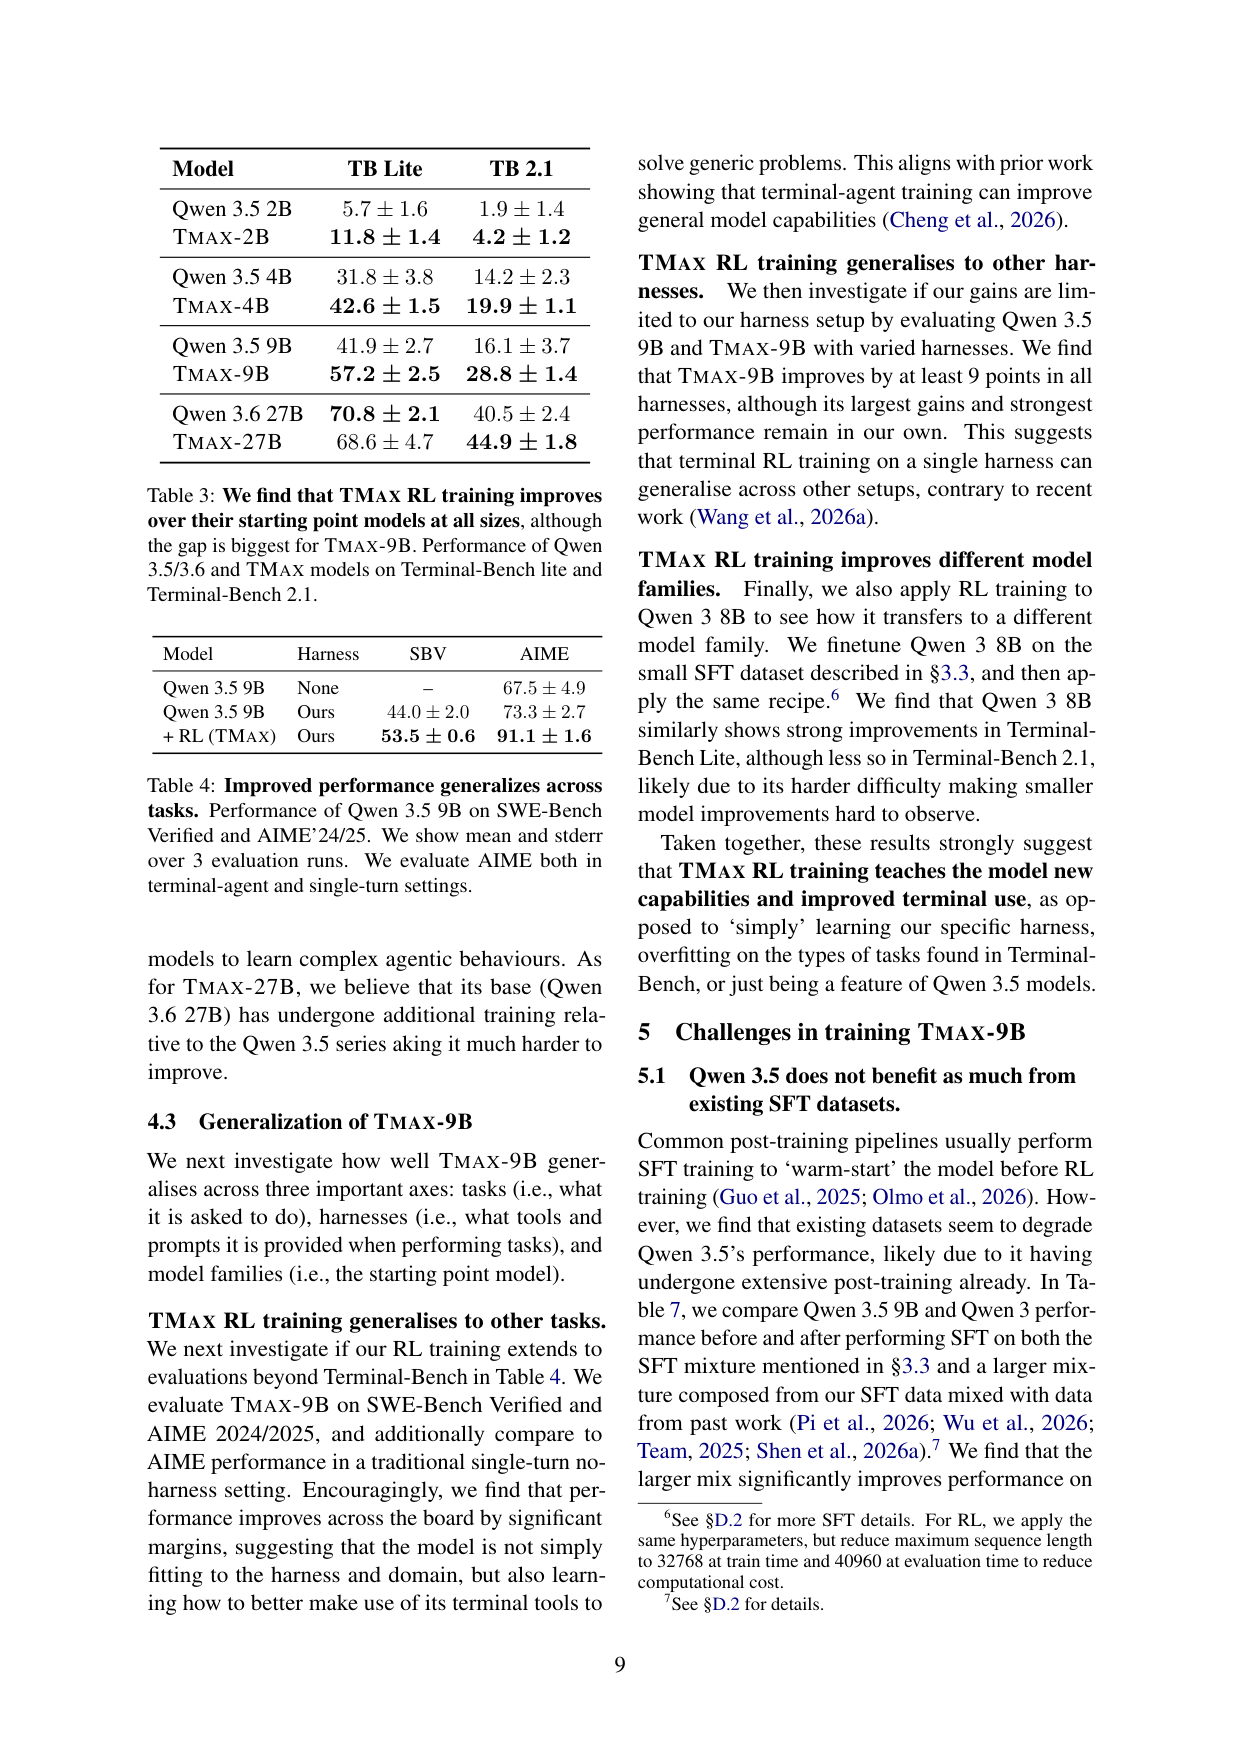

In [4]:
doc = pymupdf.open(PDF_PATH)
print(f"{PDF_PATH.name}: {len(doc)} pages")
page_pil = render_pil(doc, PAGE_NO, dpi=DPI)
page_pil

## Step 1 — heron layout

Returns a dict with `page`, `width_pt`, `height_pt`, `regions`, `fallback`.
Each region has `id`, `type`, `bbox_pt`, `bbox_px`, `score`, `column`, and an initial `order` from the XY-cut pre-sort.

In [ ]:
page_info = _extract_structure(doc, PAGE_NO, dpi=DPI)
print(f"page {PAGE_NO+1}: {len(page_info['regions'])} regions "
      f"(fallback={page_info['fallback']})")
print()
for r in page_info["regions"]:
    print(f"  {r['id']:>10}  {r['type']:<18}  bbox_pt={r['bbox_pt']}")

d:\venvs\dl\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Visualise the detected regions

In [ ]:
COLORS = {
    "text":           (30, 100, 220),
    "picture":        (220, 40, 40),
    "table":          (30, 160, 70),
    "title":          (160, 30, 180),
    "section_header": (240, 140, 30),
    "caption":        (30, 180, 180),
    "formula":        (200, 30, 160),
    "list_item":      (90, 90, 180),
    "page_header":    (120, 120, 120),
    "page_footer":    (120, 120, 120),
}
scale = DPI / 72
overlay = page_pil.copy()
draw = ImageDraw.Draw(overlay)
for r in page_info["regions"]:
    x0, y0, x1, y1 = [v * scale for v in r["bbox_pt"]]
    c = COLORS.get(r["type"], (100, 100, 100))
    draw.rectangle([x0, y0, x1, y1], outline=c, width=3)
    draw.text((x0 + 4, y0 + 4), f"{r['order']}.{r['type']}", fill=c)
overlay

## Step 2 — PaddleOCR per text region; crop pictures

- `type ∈ {picture, formula, figure}` → crop the region to a PNG, store `image_path`.
  PaddleOCR is skipped (would just return noise on a chart or photo).
- any other type → crop region, run PaddleOCR, store `text` (and `tokens` for inspection).

First instantiation downloads the PaddleOCR models (~hundreds of MB). Subsequent runs are instant.

In [ ]:
ocr = PaddleRegionOCR()

In [ ]:
stem = PDF_PATH.stem
PICTURE_TYPES = {"picture", "formula", "figure"}

for r in page_info["regions"]:
    if r["type"] in PICTURE_TYPES:
        r["image_path"] = crop_picture(doc, PAGE_NO, r, CROP_DIR, stem)
        print(f"  {r['id']}  {r['type']:<12} → {Path(r['image_path']).name}")
    else:
        toks = ocr.ocr_tokens(crop_pil(doc, PAGE_NO, r["bbox_pt"]))
        r["tokens"] = toks                           # per-word boxes, inspect if needed
        r["text"]   = join_lines(group_lines(toks))  # de-hyphenated paragraph text
        preview = r["text"][:70].replace("\n", " ")
        print(f"  {r['id']}  {r['type']:<12} {preview!r}")

## Step 3 — build the structured JSON

Normalised bbox (0–1), text for text-ish regions, `image_path` for pictures. This is what gets saved to disk as the stage-3 artefact and what feeds the planner in step 4.

In [ ]:
LABEL_PREFIX = ""   # set to e.g. "p4_" to get ids like p4_B1 (overlay + JSON stay in sync)
TAG_PREFIX   = {"picture": "F", "figure": "F", "table": "T", "formula": "E"}  # F=figure, T=table, E=equation

def build_payload(page_info):
    """Every region gets a block label B1, B2, ... (same label is drawn on the overlay image).
    Figures/pictures, tables, formulas also get a tag F1.., T1.., E1.. .
    `src_id` keeps the original heron id for downstream use (never sent to the LLM)."""
    W, H = page_info["width_pt"], page_info["height_pt"]
    regions, counters = [], {}
    for n, r in enumerate(page_info["regions"], 1):
        entry = {"id": f"{LABEL_PREFIX}B{n}", "type": r["type"], "src_id": r["id"]}
        tp = TAG_PREFIX.get(r["type"])
        if tp:
            counters[tp] = counters.get(tp, 0) + 1
            entry["tag"] = f"{tp}{counters[tp]}"
        # normalised bbox is always stored here; whether it is SENT to the LLM
        # is decided by `include_bbox` in strip_for_prompt / run_planner.
        entry["bbox"] = [
            round(r["bbox_pt"][0] / W, 4),
            round(r["bbox_pt"][1] / H, 4),
            round(r["bbox_pt"][2] / W, 4),
            round(r["bbox_pt"][3] / H, 4),
        ]
        if "image_path" in r:
            entry["image_path"] = r["image_path"]
        else:
            entry["text"] = r.get("text", "")
        regions.append(entry)
    return {
        "page":      page_info["page"],
        "width_pt":  W,
        "height_pt": H,
        "regions":   regions,
    }

payload = build_payload(page_info)
out_json = OUT_DIR / f"{PDF_PATH.stem}_p{PAGE_NO+1}.json"
out_json.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"saved {out_json}  ({out_json.stat().st_size} bytes)")
print()
print(json.dumps(payload, ensure_ascii=False, indent=2)[:2500])


## Step 4 — LLM planner for reading order

Prompt below. Edit it freely — the cell is self-contained, so iterate as you like.

What the LLM sees:
- the whole-page image (visual grounding)
- a slimmed JSON (ids, types, normalised bboxes, optional truncated text — `image_path`   stripped because the LLM can't open local files)

What it returns:
- `{"order": [...region_ids]}` — ids in reading order.

Blocks are labelled B1, B2, ... in BOTH the overlay image and the JSON; figures/tables/formulas also carry F#/T#/E# tags. `USE_BBOX` (cell below) toggles sending bbox.

In [ ]:
PLAN_PROMPT = (
    "You are given ONE document page: the page image, where every detected block "
    "is boxed and labelled (B1, B2, ...), and a JSON list of those blocks. "
    "Output the reading order of the blocks.\n"
    "JSON fields: id (the label drawn on the image), type (title, section_header, "
    "text, list_item, caption, footnote, table, picture, figure, formula, "
    "page_header, page_footer, page_number), tag (only on figures/pictures F#, "
    "tables T#, formulas E#), text (long texts are given as text_start + "
    "text_end, the middle is omitted). Pictures, tables and formulas carry no "
    "text. The JSON list is NOT in reading order. Find every block on the image "
    "by its id.\n"
    "\n"
    "STEP 1 - LAYOUT. Look at the image first and decide the layout from the "
    "boxes: single column; two or more columns; full-width blocks above, below "
    "or between columns; images/tables side by side; image beside text; or a "
    "mix that changes down the page. Split the page into horizontal ZONES, top "
    "to bottom, wherever a full-width block spans the page or the column "
    "structure changes. Reading rules inside a zone:\n"
    "- single column: top to bottom.\n"
    "- 2 columns: read the LEFT column completely, top to bottom, then "
    "the next column to its right. NEVER read across a row of a "
    "2-column zone. Don't Let the bounding box in image affect your 2 column page layout\n"
    "- blocks side by side in one row (e.g. two images): left to right.\n"
    "\n"
    "STEP 2 - BASE ORDER. After the layout is determined in the order from Step 1 then,"
    "Zones top to bottom(single column), If two columns left column(top to bottom) then right column(top to bottom). "
    "A caption stays with its figure/picture (object, then caption) and with "
    "its table (caption on the side of the table where it sits). A formula "
    "stays where it sits in its column. A title or section_header stays "
    "directly before the text it introduces.\n"
    "\n"
    "STEP 3 - TEXT CONTINUITY. This is the only thing allowed to change the "
    "base order subject to the rules below.(MUST CHECK)\n"
    "A. Page start. Take the first text block of the page in base order "
    "(ignore header/footer/page number/image/caption/table..). If it starts mid-sentence (word "
    "fragment or lowercase continuation) it continues the previous page: put "
    "it FIRST, before any figure, picture, table or caption, even if those are "
    "higher on the page. Every figure/table (with its caption) that was moved "
    "behind it goes right after that continuation block (if the block is "
    "itself cut off, after the block that completes it). If the first text "
    "block starts a fresh sentence or is a heading, change nothing.\n"
    "B. Column break. Only the LAST text block of a column can continue into "
    "the FIRST text block of the next column. If that last block ends cut off "
    "(mid-word, no end punctuation, dangling clause) and the first block of the "
    "next column reads as its continuation, place that block immediately after "
    "it; any figure/table lying between them goes after the continued block "
    "ends. Verify: the end of the first block followed by the start of the "
    "second must read as one sentence. A block that has another text block "
    "below it in its own column never continues into another column.\n"
    "C. A missing final period alone is NOT a cut-off (OCR drops them): if the "
    "next block in the same column starts a new sentence or paragraph, the "
    "block is complete. On weak or ambiguous evidence keep the base order.\n"
    "So, Atleast for starting few and last block llm has to read the given text from json and decide whether it is a continuation or not."
    "One such example: picture block followed caption, then text block. If the text block is a continuation of the previous page, it should be placed first, followed by the image and caption"
    "\n"
    "STEP 4 - HEADER / FOOTER / PAGE NUMBER. Footnotes go after the body text. "
    "Then page_header, page_footer, page_number, in that order, at the very "
    "end. Exception: if the LAST body text block of the page is cut off "
    "mid-sentence (it continues on the next page), that block must be the very "
    "last item, so put the header/footer/page number immediately BEFORE it. "
    "Do not look for its continuation on this page.\n"
    "\n"
    "RULES: every id appears exactly once; use only ids from the list.\n"
    "Return ONLY this JSON, no prose, no code fences. You MUST evaluate the text continuity and layout rules explicitly in the 'evaluation' field BEFORE outputting the order:\n"
    '{\n'
    '  "layout": "<ASCII sketch of the zones, top to bottom: / between zones, | between columns>", \n'
    '  "zones": [{"columns": [[ids in column order], ...]}], \n'
    '  "order": [ids]\n'
    '  "evaluation": {\n'
    '    "page_start_check": "<Identify the first base-order text block. Does it start mid-sentence or lowercase? If yes, state that it must be moved to the front.>",\n'
    '    "column_break_check": "<Identify the last text block of the left column. Does it cut off? Does the right column complete it?>"\n'
    '  },\n'
    '}\n'

    
)

# Appended only when include_bbox=True (decide later based on performance).
BBOX_NOTE = (
    "\nEach region also has bbox [x0,y0,x1,y1], normalized to [0,1] with the "
    "origin at the top-left. Use it together with the image to assign blocks "
    "to zones and columns.\n"
)

REGIONS_HEADER = "\nRegions:\n"


### Helpers: what to send, what to parse

In [ ]:
NO_TEXT_TYPES = {"picture", "figure", "formula", "table"}   # their content is irrelevant for ordering

def strip_for_prompt(payload, include_text=True, include_bbox=False, head=150, tail=150):
    """Shape the regions JSON we actually send to the LLM.

    - ids are the block labels (B1, B2, ...) that are drawn on the overlay image
    - `tag` (F#/T#/E#) is kept for figures, tables, formulas
    - `bbox` is sent only if include_bbox=True
    - long texts are sent as text_start + text_end, because the END of a block
      is what reveals a sentence continuing into the next column/page
    - src_id / image_path / bbox_pt are never sent
    """
    out = []
    for r in payload["regions"]:
        e = {"id": r["id"], "type": r["type"]}
        if "tag" in r:
            e["tag"] = r["tag"]
        if include_bbox and "bbox" in r:
            e["bbox"] = r["bbox"]
        if include_text and "text" in r and r["type"] not in NO_TEXT_TYPES:
            t = r["text"]
            if len(t) <= head + tail:
                e["text"] = t
            else:
                e["text_start"] = t[:head]
                e["text_end"]   = t[-tail:]
        out.append(e)
    return out


def parse_order(text, known_ids):
    """Extract {"order": [...]} from the model response.
    Filters to known ids, drops duplicates, appends any missing id at the end."""
    m = re.search(r"\{.*\}", text, re.S)
    if not m:
        return [], None
    try:
        j = json.loads(m.group(0))
    except json.JSONDecodeError:
        return [], None
    ret = j.get("order") if isinstance(j.get("order"), list) else []
    seen, order = set(), []
    for i in ret:
        if i in known_ids and i not in seen:
            order.append(i); seen.add(i)
    order += [i for i in known_ids if i not in seen]
    return order, j


def run_planner(model_id, prompt, pil, regions_slim, include_bbox=False):
    client = OpenRouterClient(model=model_id)
    full_prompt = (
        prompt
        + (BBOX_NOTE if include_bbox else "")
        + REGIONS_HEADER
        + json.dumps(regions_slim, ensure_ascii=False)
    )
    text   = client.vision_chat(full_prompt, pil)
    known  = [r["id"] for r in regions_slim]
    order, parsed = parse_order(text, known)
    return order, text


In [ ]:
from PIL import ImageFont

def annotate_page(page_pil, page_info, payload, dpi=DPI):
    """Page image with EVERY block boxed and labelled with its block id (B1, B2, ...),
    exactly the same ids as in the JSON sent to the LLM."""
    img = page_pil.copy().convert("RGB")
    d = ImageDraw.Draw(img)
    s = dpi / 72
    try:
        font = ImageFont.truetype("arial.ttf", 26)
    except OSError:
        font = ImageFont.load_default()
    by_src = {r["id"]: r for r in page_info["regions"]}
    for e in payload["regions"]:
        r = by_src[e["src_id"]]
        x0, y0, x1, y1 = [v * s for v in r["bbox_pt"]]
        d.rectangle([x0, y0, x1, y1], outline=(220, 40, 40), width=3)
        tb = d.textbbox((x0 - 15, y0 - 18), e["id"], font=font)
        d.rectangle(tb, fill=(255, 255, 255))
        d.text((x0 - 15, y0 - 18), e["id"], fill=(220, 40, 40), font=font)
    return img

annotated_pil = annotate_page(page_pil, page_info, payload)
annotated_pil   # preview: this is the image the planner receives


### Run one model

In [ ]:
USE_BBOX = True     # flip to True to also send normalised bbox (+ BBOX_NOTE) to the LLM

regions_slim = strip_for_prompt(payload, include_text=True, include_bbox=USE_BBOX, head=150, tail=150)

order, raw_text = run_planner(
    "google/gemini-2.5-flash",
    PLAN_PROMPT,
    annotated_pil,
    regions_slim,
    include_bbox=USE_BBOX,
)
print("ORDER:", order)
print()
print("RAW RESPONSE:")
print(raw_text[:1500])


### Pretty-print the ordered page

In [ ]:
def pretty_print(order, payload, max_preview=100):
    idmap = {r["id"]: r for r in payload["regions"]}
    for i, rid in enumerate(order, 1):
        r = idmap[rid]
        tag = f" {r['tag']}" if "tag" in r else ""
        content = (r.get("text") or f"[{r['type'].upper()}{tag}]")[:max_preview].replace("\n", " ")
        print(f"{i:2}. {rid:<5} [{r['type']:<15}] {content}")

pretty_print(order, payload)


### Compare models side-by-side

Uncomment the ones you want to try. Model IDs follow OpenRouter's naming; if an id 404s, check [openrouter.ai/models](https://openrouter.ai/models) for the current one. All of these are vision-capable.

In [ ]:
# MODELS = [
#     # "google/gemini-2.5-flash",         # fast, cheap, strong vision — the default
#     # "google/gemini-2.5-pro",           # stronger reasoning, slower, pricier
#     # "qwen/qwen2.5-vl-72b-instruct",    # open-source Qwen VL (large)
#     "qwen/qwen2.5-vl-32b-instruct",  # open-source Qwen VL (smaller)
#     "meta-llama/llama-3.2-90b-vision-instruct",  # open-source Llama vision
#     # "openai/gpt-4o",                 # pricey baseline
#     # "openai/gpt-4o-mini",            # cheap OpenAI
# ]

MODELS = [
    # "nvidia/nemotron-3.5-super-vl:free",
    "nvidia/nemotron-3.5-super-vl"
    # "qwen/qwen2.5-vl-72b-instruct",        # control: it worked before, so a failure here is a prompt/pipeline issue
    # "google/gemma-4-31b-it",               # newest open Gemma, $0.20/M
    # "google/gemma-3-27b-it",               # older open Gemma, $0.08/M
    # "meta-llama/llama-4-maverick",         # open Llama, $0.19/M
    # "meta-llama/llama-4-scout",            # smaller Llama, $0.10/M
    # "mistralai/mistral-small-2603",        # cheap Mistral, $0.15/M
    # "mistralai/mistral-medium-3.1",        # stronger Mistral, $0.40/M
    # "z-ai/glm-5v-turbo",                 # strongest vision here, but $1.20/M
]

results = {}
for m in MODELS:
    print(f"=== {m} ===")
    try:
        o, _ = run_planner(m, PLAN_PROMPT, annotated_pil, regions_slim, include_bbox=USE_BBOX)
        results[m] = o
        pretty_print(o, payload, max_preview=60)
    except Exception as e:
        print(f"  FAILED: {type(e).__name__}: {str(e)[:200]}")
    print()


In [ ]:
_

## Step 5 — save the ordered result

In [ ]:
MODEL_USED = "google/gemini-2.5-flash"
final_order = results.get(MODEL_USED) or order

ordered_payload = {
    "pdf":    str(PDF_PATH),
    "page":   PAGE_NO + 1,
    "model":  MODEL_USED,
    "order":  final_order,
    "regions": payload["regions"],   # includes text / image_path per region
}

out_path = OUT_DIR / f"{PDF_PATH.stem}_p{PAGE_NO+1}_ordered.json"
out_path.write_text(json.dumps(ordered_payload, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"saved {out_path}")

## Where to go next

- **Iterate on `PLAN_PROMPT`** — rerun step 4, pretty-print, repeat.
- **Try a different page** — change `PAGE_NO` and rerun from step 1.
- **Try a different PDF** — change `PDF_PATH` and rerun from step 1.
- **Try `include_text=False`** in `strip_for_prompt` — cheaper, image-only grounding.
- **Loop over all pages** — wrap steps 1–5 in `for pno in range(len(doc)): ...` and   you've essentially reimplemented `DigitalEnglishPipeline.process` with per-page JSON saved.

Once a prompt/model combo looks good, port the `PLAN_PROMPT` back into `src/pipelines/digital_english.py` and set `OPENROUTER_MODEL=…` in `.env`.

In [ ]:

# import pymupdf
# import time

# PDF_PATH = "pdf/complex.pdf"

# doc = pymupdf.open(PDF_PATH)

# start = time.perf_counter()

# for page_num, page in enumerate(doc, start=1):
#     print("\n" + "=" * 80)
#     print(f"PAGE {page_num} / {len(doc)}")
#     print("=" * 80)

#     # Extract the existing PDF text; no OCR is performed.
#     data = page.get_text("dict", sort=True)

#     for block in data["blocks"]:
#         # Skip image blocks; process text blocks only.
#         if "lines" not in block:
#             continue

#         for line in block["lines"]:
#             line_text = "".join(
#                 span["text"] for span in line["spans"]
#             )
#             if line_text.strip():
#                 print(line_text)

# elapsed = time.perf_counter() - start

# print("\n" + "=" * 80)
# print(f"Pages: {len(doc)}")
# print(f"Extraction time: {elapsed:.3f}s")
# print("=" * 80)

# doc.close()


In [ ]:
import os
import json
import base64
import time
import requests
import fitz  # PyMuPDF
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from PIL import Image
from io import BytesIO


# ============================================================
# 1. CONFIGURATION
# ============================================================

PDF_PATH = "pdf/telugu_eng_scanned.pdf"
PAGE_NO = 3                     # Zero-based page index
DPI = 180

API_KEY = os.getenv("BODHAN_OCR_API_KEY")
API_URL = "https://api.bodhan.ai/v1/chat/completions"
MODEL = "indic-ocr"

OVERLAP_THRESHOLD = 0.95
MAX_TOKENS = 4096
MAX_RETRIES = 3

OUTPUT_DIR = "explore_out"
os.makedirs(OUTPUT_DIR, exist_ok=True)

RAW_JSON_PATH = os.path.join(
    OUTPUT_DIR, f"tmax_p{PAGE_NO + 1}.json"
)
FILTERED_JSON_PATH = os.path.join(
    OUTPUT_DIR, f"tmax_p{PAGE_NO + 1}_filtered.json"
)
IMAGE_PATH = os.path.join(
    OUTPUT_DIR, f"bbox_p{PAGE_NO + 1}.png"
)


# ============================================================
# 2. RENDER PDF PAGE
# ============================================================

if not os.path.isfile(PDF_PATH):
    raise FileNotFoundError(f"PDF not found: {PDF_PATH}")

with fitz.open(PDF_PATH) as pdf:
    if not 0 <= PAGE_NO < len(pdf):
        raise IndexError(
            f"PAGE_NO={PAGE_NO} is invalid. "
            f"PDF has {len(pdf)} pages."
        )

    page = pdf[PAGE_NO]
    pdf_width = page.rect.width
    pdf_height = page.rect.height

    pix = page.get_pixmap(
        matrix=fitz.Matrix(DPI / 72, DPI / 72),
        alpha=False,
    )

    image = Image.open(
        BytesIO(pix.tobytes("png"))
    ).convert("RGB")

image_width, image_height = image.size

print(f"Page: {PAGE_NO + 1}")
print(f"Rendered image: {image_width} × {image_height}")
print(f"PDF dimensions: {pdf_width:.1f} × {pdf_height:.1f} pt")


# ============================================================
# 3. ENCODE IMAGE FOR API
# ============================================================

if not API_KEY:
    raise EnvironmentError(
        "BODHAN_OCR_API_KEY is not set. "
        "Set it as an environment variable before running."
    )

buffer = BytesIO()
image.save(buffer, format="PNG")
image_bytes = buffer.getvalue()

image_b64 = base64.b64encode(image_bytes).decode("utf-8")

headers = {
    "Authorization": f"Bearer {API_KEY}",
    "Content-Type": "application/json",
}

payload = {
    "model": MODEL,
    "messages": [
        {
            "role": "user",
            "content": [
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/png;base64,{image_b64}"
                    },
                }
            ],
        }
    ],
    "max_tokens": MAX_TOKENS,
}


# ============================================================
# 4. CALL OCR API WITH RETRIES FOR TRANSIENT ERRORS
# ============================================================

api_result = None

for attempt in range(1, MAX_RETRIES + 1):
    try:
        print(f"\nOCR request: attempt {attempt}/{MAX_RETRIES}")

        response = requests.post(
            API_URL,
            headers=headers,
            json=payload,
            timeout=180,
        )

        print("HTTP status:", response.status_code)
        print("Request ID:", response.headers.get("x-request-id"))

        if response.ok:
            try:
                api_result = response.json()
            except requests.exceptions.JSONDecodeError:
                print("API returned non-JSON content:")
                print(response.text[:3000])
                response.raise_for_status()

            break

        # Print the actual server response for diagnosis.
        print("API error details:")
        print(response.text[:5000])

        # Retry transient server errors only.
        if response.status_code in (502, 503, 504, 429):
            if attempt < MAX_RETRIES:
                wait_seconds = 2 ** attempt
                print(f"Retrying in {wait_seconds} seconds...")
                time.sleep(wait_seconds)
                continue

        response.raise_for_status()

    except requests.exceptions.Timeout:
        print("Request timed out.")

        if attempt == MAX_RETRIES:
            raise

        time.sleep(2 ** attempt)

    except requests.exceptions.ConnectionError:
        print("Connection error.")

        if attempt == MAX_RETRIES:
            raise

        time.sleep(2 ** attempt)

if api_result is None:
    raise RuntimeError("OCR API did not return a successful response.")

with open(RAW_JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(api_result, f, ensure_ascii=False, indent=2)

print(f"\nSaved raw API response: {RAW_JSON_PATH}")


# ============================================================
# 5. EXTRACT OCR REGIONS
# ============================================================

def extract_regions(data):
    """Extract a list of regions from common JSON response formats."""

    if isinstance(data, list):
        return data

    if not isinstance(data, dict):
        return []

    # Common direct layout fields.
    for key in ("regions", "blocks", "elements", "layout"):
        value = data.get(key)
        if isinstance(value, list):
            return value

    # OpenAI-compatible chat completion.
    choices = data.get("choices")

    if isinstance(choices, list) and choices:
        message = choices[0].get("message", {})
        content = message.get("content")

        if isinstance(content, str):
            content = content.strip()

            if content.startswith("```"):
                lines = content.splitlines()

                if lines and lines[0].startswith("```"):
                    lines = lines[1:]

                if lines and lines[-1].strip() == "```":
                    lines = lines[:-1]

                content = "\n".join(lines)

            try:
                parsed = json.loads(content)
                regions = extract_regions(parsed)

                if regions:
                    return regions

            except json.JSONDecodeError:
                pass

    # Common wrapper fields.
    for key in ("data", "result", "output", "response"):
        if key in data:
            regions = extract_regions(data[key])

            if regions:
                return regions

    return []


blocks = extract_regions(api_result)

if not blocks:
    print("\nCould not locate regions in the API response.")
    print("Response preview:")
    print(json.dumps(api_result, ensure_ascii=False, indent=2)[:5000])

    raise ValueError(
        "No OCR regions found. Inspect the raw JSON and adapt "
        "extract_regions() to the actual API response schema."
    )

print("Regions returned:", len(blocks))


# ============================================================
# 6. BOUNDING BOX CONVERSION
# Internal representation: [x1, y1, x2, y2] in image pixels.
# ============================================================

def normalize_bbox(
    bbox,
    image_width,
    image_height,
    pdf_width,
    pdf_height,
):
    if isinstance(bbox, dict):

        if all(k in bbox for k in ("x1", "y1", "x2", "y2")):
            values = [
                bbox["x1"], bbox["y1"],
                bbox["x2"], bbox["y2"],
            ]

        elif all(k in bbox for k in ("x", "y", "width", "height")):
            x, y = bbox["x"], bbox["y"]
            values = [
                x, y,
                x + bbox["width"],
                y + bbox["height"],
            ]

        elif all(k in bbox for k in ("left", "top", "right", "bottom")):
            values = [
                bbox["left"], bbox["top"],
                bbox["right"], bbox["bottom"],
            ]

        else:
            return None

    elif isinstance(bbox, (list, tuple)) and len(bbox) == 4:
        values = list(bbox)

    else:
        return None

    try:
        x1, y1, x2, y2 = map(float, values)
    except (TypeError, ValueError):
        return None

    # Some APIs provide center-x, center-y, width, height instead.
    # Do not interpret that format as XYXY; configure separately
    # if the API documentation specifies center-based coordinates.

    # Sort coordinates.
    x1, x2 = min(x1, x2), max(x1, x2)
    y1, y2 = min(y1, y2), max(y1, y2)

    # Normalized coordinates in [0, 1].
    if (
        0 <= x1 <= 1 and 0 <= x2 <= 1
        and 0 <= y1 <= 1 and 0 <= y2 <= 1
    ):
        x1 *= image_width
        x2 *= image_width
        y1 *= image_height
        y2 *= image_height

    # PDF points converted to image pixels.
    elif (
        x2 <= pdf_width + 2
        and y2 <= pdf_height + 2
        and (
            abs(pdf_width - image_width) > 2
            or abs(pdf_height - image_height) > 2
        )
    ):
        scale_x = image_width / pdf_width
        scale_y = image_height / pdf_height

        x1 *= scale_x
        x2 *= scale_x
        y1 *= scale_y
        y2 *= scale_y

    # Otherwise assume image pixel coordinates.

    # Clip to the image.
    x1 = max(0, min(x1, image_width))
    x2 = max(0, min(x2, image_width))
    y1 = max(0, min(y1, image_height))
    y2 = max(0, min(y2, image_height))

    if x2 <= x1 or y2 <= y1:
        return None

    return [x1, y1, x2, y2]


def find_bbox(block):
    if not isinstance(block, dict):
        return None

    for key in (
        "bbox",
        "bbox_xyxy",
        "bounding_box",
        "box",
        "coordinates",
    ):
        if key in block:
            bbox = normalize_bbox(
                block[key],
                image_width,
                image_height,
                pdf_width,
                pdf_height,
            )

            if bbox is not None:
                return bbox

    return None


valid_blocks = []
invalid_count = 0

for index, block in enumerate(blocks):
    bbox = find_bbox(block)

    if bbox is None:
        invalid_count += 1
        continue

    valid_blocks.append({
        "block": block,
        "bbox": bbox,
        "original_index": index,
    })

print("Valid bounding boxes:", len(valid_blocks))
print("Invalid/missing bounding boxes:", invalid_count)


# ============================================================
# 7. OVERLAP FILTER
# Remove a smaller box if >95% of its area is covered by
# a larger box. This uses candidate coverage, not IoU.
# ============================================================

def box_area(box):
    x1, y1, x2, y2 = box
    return max(0, x2 - x1) * max(0, y2 - y1)


def intersection_area(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    x1 = max(ax1, bx1)
    y1 = max(ay1, by1)
    x2 = min(ax2, bx2)
    y2 = min(ay2, by2)

    if x2 <= x1 or y2 <= y1:
        return 0.0

    return (x2 - x1) * (y2 - y1)


def remove_nested_overlaps(items, threshold=0.95):
    candidates = sorted(
        items,
        key=lambda item: box_area(item["bbox"]),
        reverse=True,
    )

    kept = []
    removed = []

    for candidate in candidates:
        candidate_box = candidate["bbox"]
        candidate_area = box_area(candidate_box)

        if candidate_area <= 0:
            removed.append({
                **candidate,
                "reason": "zero-area box",
                "overlap_fraction": 0.0,
            })
            continue

        best_coverage = 0.0
        suppressor = None

        for larger in kept:
            overlap = intersection_area(
                candidate_box,
                larger["bbox"],
            )

            coverage = overlap / candidate_area

            if coverage > best_coverage:
                best_coverage = coverage
                suppressor = larger

            if coverage > threshold:
                break

        if best_coverage > threshold:
            removed.append({
                **candidate,
                "reason": "covered by larger box",
                "overlap_fraction": best_coverage,
                "suppressed_by_index": suppressor["original_index"],
            })
        else:
            kept.append(candidate)

    return kept, removed


kept_blocks, removed_blocks = remove_nested_overlaps(
    valid_blocks,
    threshold=OVERLAP_THRESHOLD,
)

print("\nOverlap filtering results")
print("-------------------------")
print("Before:", len(valid_blocks))
print("Removed:", len(removed_blocks))
print("Remaining:", len(kept_blocks))

for item in removed_blocks:
    block = item["block"]

    label = (
        block.get("type")
        or block.get("label")
        or block.get("text")
        or "region"
    )

    print(
        f"Removed #{item['original_index']}: "
        f"{str(label)[:50]!r}, "
        f"coverage={item['overlap_fraction']:.3f}, "
        f"bbox={[round(v, 1) for v in item['bbox']]}"
    )


# ============================================================
# 8. DRAW FILTERED BOXES
# ============================================================

fig, ax = plt.subplots(figsize=(14, 18))

ax.imshow(image)
ax.set_xlim(0, image_width)
ax.set_ylim(image_height, 0)
ax.axis("off")

for item in kept_blocks:
    block = item["block"]
    x1, y1, x2, y2 = item["bbox"]

    label = (
        block.get("type")
        or block.get("label")
        or block.get("category")
        or "region"
    )

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=1.5,
        edgecolor="red",
        facecolor="none",
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        max(0, y1 - 4),
        str(label)[:45],
        color="white",
        fontsize=7,
        bbox={
            "facecolor": "red",
            "alpha": 0.75,
            "pad": 1,
        },
    )

plt.tight_layout()
fig.savefig(
    IMAGE_PATH,
    dpi=150,
    bbox_inches="tight",
)
plt.show()

print("\nSaved visualization:", IMAGE_PATH)


# ============================================================
# 9. SAVE FILTERED JSON
# ============================================================

filtered_result = {
    "page": PAGE_NO + 1,
    "image_width": image_width,
    "image_height": image_height,
    "overlap_threshold": OVERLAP_THRESHOLD,
    "regions_before_filtering": len(valid_blocks),
    "regions_removed": len(removed_blocks),
    "regions_remaining": len(kept_blocks),

    "regions": [
        {
            **item["block"],
            "bbox_xyxy_pixels": [
                round(v, 2) for v in item["bbox"]
            ],
        }
        for item in kept_blocks
    ],

    "removed_regions": [
        {
            **item["block"],
            "bbox_xyxy_pixels": [
                round(v, 2) for v in item["bbox"]
            ],
            "overlap_fraction": round(
                item["overlap_fraction"], 5
            ),
            "reason": item["reason"],
            "suppressed_by_index": item.get(
                "suppressed_by_index"
            ),
        }
        for item in removed_blocks
    ],
}

with open(FILTERED_JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(
        filtered_result,
        f,
        ensure_ascii=False,
        indent=2,
    )

print("Saved filtered JSON:", FILTERED_JSON_PATH)

In [ ]:
# import os
# import requests

# def check_openrouter():
#     key = os.getenv("OPENROUTER_API_KEY")
#     if not key:
#         print("Set OPENROUTER_API_KEY first.")
#         return

#     r = requests.get(
#         "https://openrouter.ai/api/v1/key",
#         headers={"Authorization": f"Bearer {key}"},
#         timeout=20,
#     )
#     r.raise_for_status()
#     data = r.json()["data"]

#     print("\n--- OpenRouter API Key ---")
#     print(f"Key:             {data.get('label', 'N/A')}")
#     print(f"Total usage:     ${data.get('usage', 0):.6f}")
#     print(f"Today's usage:   ${data.get('usage_daily', 0):.6f}")
#     print(f"This week:       ${data.get('usage_weekly', 0):.6f}")
#     print(f"This month:      ${data.get('usage_monthly', 0):.6f}")

#     limit = data.get("limit")
#     remaining = data.get("limit_remaining")

#     if limit is None:
#         print("Key spending cap: Unlimited / not configured")
#     else:
#         print(f"Key spending cap: ${limit:.6f}")
#         print(f"Key cap remaining: ${remaining:.6f}"
#               if remaining is not None else "Key cap remaining: N/A")

#     print("\nNote: The remaining key cap is NOT necessarily your total account balance.")
#     print("For total account credits, use a management key or the OpenRouter dashboard.")

# check_openrouter()